# LMM scenarios from BasicLMM

This notebook runs the BasicLMM model on `lmm_input.xlsx` and shows what its scenarios
look like:

1. the inputs, and the caplet volatilities the volatility table gives,
2. fan charts of LIBOR rates and 10-year yields,
3. a check that the deflators reproduce the initial curve,
4. caplets against Black's formula,
5. the distribution of the 10-year yield at three horizons,
6. how the tenor of the forward rates changes the bank account,
7. the bond fund that drives the liability model,
8. the summary of the `Validation` space.

The model reads `lmm_input.xlsx` from the library folder, which holds this notebook;
edit the workbook there and run all cells again to see another input.

Click the badge below to run this notebook online on Google Colab. You need a Google account and need to be logged in to it to run this notebook on Google Colab.
[![Run on Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lifelib-dev/lifelib/blob/current/lifelib/libraries/economic/lmm-simulation.ipynb)


The next code cell below is relevant only when you run this notebook on Google Colab. It installs lifelib and creates a copy of the library for this notebook.

In [1]:
import sys, os

if 'google.colab' in sys.modules:
    lib = 'economic'; lib_dir = '/content/'+ lib
    if not os.path.exists(lib_dir):
        !pip install lifelib
        import lifelib; lifelib.create(lib, lib_dir)

    %cd $lib_dir

In [2]:
import matplotlib.pyplot as plt
import modelx as mx
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MultipleLocator

model = mx.read_model("BasicLMM")
lmm, validation = model.LMM, model.Validation
N, n, p = lmm.scen_size(), lmm.step_size(), lmm.tenor_mth()
years = np.arange(n + 1) / 12
print(f"{N:,} stochastic scenarios plus the CE scenario, {n} months ({n / 12:g} years), "
      f"forward rates of {p} months")

1,000 stochastic scenarios plus the CE scenario, 600 months (50 years), forward rates of 12 months


In [3]:
# Chart style: light-mode tokens of the reference palette, slot 1 (blue) for the
# stochastic scenarios and slot 2 (orange) for the certainty-equivalent (CE) scenario.
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titlelocation": "left", "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "legend.frameon": False,
    "legend.labelcolor": INK_2, "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "figure.dpi": 110, "font.size": 9.5,
})

BANDS = [("1st", 1, "99th", 99), ("5th", 5, "95th", 95), ("25th", 25, "75th", 75)]
WASH = 0.10                              # nested percentile bands, each a 10% wash


def fan(ax, paths, x):
    """Percentile bands and median of the stochastic rows of paths, and the CE row."""
    stochastic = paths[1:]
    for _, lo, _, hi in BANDS:
        ax.fill_between(x, np.percentile(stochastic, lo, axis=0),
                        np.percentile(stochastic, hi, axis=0),
                        color=BLUE, alpha=WASH, linewidth=0)
    ax.plot(x, np.median(stochastic, axis=0), color=BLUE)
    ax.plot(x, paths[0], color=ORANGE)


def fan_legend(target, **kwargs):
    """Legend for fan() on an axes or a figure; nested bands show the opacity they build up to."""
    handles = [Patch(color=BLUE, alpha=1 - (1 - WASH) ** k, linewidth=0,
                     label=f"{lo} to {hi} percentile")
               for k, (lo, _, hi, _) in enumerate(BANDS, start=1)]
    handles += [Line2D([], [], color=BLUE, label="median"),
                Line2D([], [], color=ORANGE, label="CE scenario")]
    target.legend(handles=handles, **kwargs)


def percent_axis(axis, step, decimals=0):
    """Percent labels at multiples of step, without a "-0%"."""
    axis.set_major_locator(MultipleLocator(step))
    axis.set_major_formatter(FuncFormatter(
        lambda v, _: f"{0.0 if abs(v) < 1e-12 else v:.{decimals}%}"))


def percentile_table(paths, at_years, scale=100, decimals=2):
    """Table view of a fan chart: CE value and percentiles at the given years."""
    idx = [int(round(y * 12)) for y in at_years]
    stochastic = paths[1:, idx]
    table = pd.DataFrame({f"p{q}": np.percentile(stochastic, q, axis=0)
                          for q in (1, 5, 25, 50, 75, 95, 99)},
                         index=pd.Index(at_years, name="year"))
    table.insert(0, "CE", paths[0, idx])
    return (scale * table).round(decimals)

## Inputs

The run settings from the `Params` sheet, a few points of the selected curve, the
volatility table and the selected fund. The example shift and volatility table are
illustrative, not calibrated.

In [4]:
display(lmm.param_table().to_frame("value"))
curve = lmm.curve_table()[lmm.curve_id()].dropna()
shown = [m for m in (1, 5, 10, 20, 30, 50, 100, 150) if m in curve.index]
print(f"Curve {lmm.curve_id()}, {lmm.compounding()} compounding, spot rates in %:")
display((100 * curve.loc[shown]).round(3).to_frame("spot rate (%)"))
print(f"Fund {lmm.fund_id()}: {lmm.fund_cash_share():.0%} cash, and bonds by months to maturity:")
display(lmm.fund_bond_shares().to_frame("share"))

,value
parameter,
shift,0.02
tenor_mth,12
maturity_size,120
scen_size,1000
step_size,600
seed,1234
antithetic,True
curve_id,EUR_BASE
compounding,annual


Curve EUR_BASE, annual compounding, spot rates in %:


,spot rate (%)
maturity,
1.0,3.357
5.0,2.323
10.0,2.393
20.0,2.406
30.0,2.534
50.0,2.847
100.0,3.145
150.0,3.247


Fund BOND_MIX: 20% cash, and bonds by months to maturity:


,share
months,
60,0.3
120,0.5


Each row of the `Vol` sheet is the volatility vector of a forward rate with that time
to expiry, one column per factor. Its length is the rate's volatility, shown on the left
with the two loadings. The volatility falls with the time to expiry, which keeps rates in
a plausible range over long horizons. The right panel shows the Black volatility of each
caplet, `caplet_vol`: the average of the squared volatility over a rate's life, so it
falls more slowly. Caplets on rates with the same expiry, F + shift being lognormal, are
priced by Black's formula with this volatility.

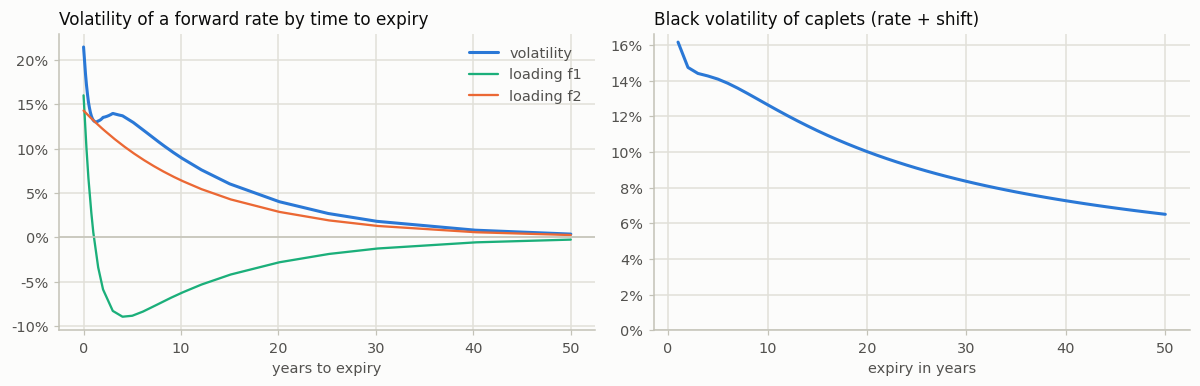

Caplet volatilities (%): {1: 16.2, 5: 14.1, 10: 12.6, 20: 10.0, 30: 8.3, 50: 6.5}


In [5]:
vol = lmm.vol_table()
u = np.linspace(0, 50, 501)
loadings = np.column_stack([np.interp(u, vol.index, vol[c]) for c in vol.columns])
expiry_years = np.arange(1, n // 12 + 1)
ks = [12 * y // p + 1 for y in expiry_years]
caplet_vols = [lmm.caplet_vol(k) for k in ks]

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
left.plot(u, np.linalg.norm(loadings, axis=1), color=BLUE, label="volatility")
for q, (col, color) in enumerate(zip(vol.columns, [GREEN, ORANGE])):
    left.plot(u, loadings[:, q], color=color, linewidth=1.5, label=f"loading {col}")
left.axhline(0, color=AXIS, linewidth=1)
left.set_title("Volatility of a forward rate by time to expiry")
left.set_xlabel("years to expiry")
percent_axis(left.yaxis, 0.05)
left.legend(loc="upper right")
right.plot(expiry_years, caplet_vols, color=BLUE)
right.set_title("Black volatility of caplets (rate + shift)")
right.set_xlabel("expiry in years")
right.set_ylim(0, None)
percent_axis(right.yaxis, 0.02)
fig.tight_layout()
plt.show()
print("Caplet volatilities (%):",
      {int(y): round(100 * v, 1) for y, v in zip(expiry_years, caplet_vols) if y in (1, 5, 10, 20, 30, 50)})

## LIBOR rates and 10-year yields

Each band holds the given share of the stochastic scenarios at each month. The LIBOR rate
is the simply compounded rate for one tenor; on a tenor date it is the forward rate just
set. The CE scenario follows the initial forward curve. Rates are shifted lognormal, so
they stay above minus the shift, and their spread grows with the level of rates; the
upper tail is longer than the lower one.

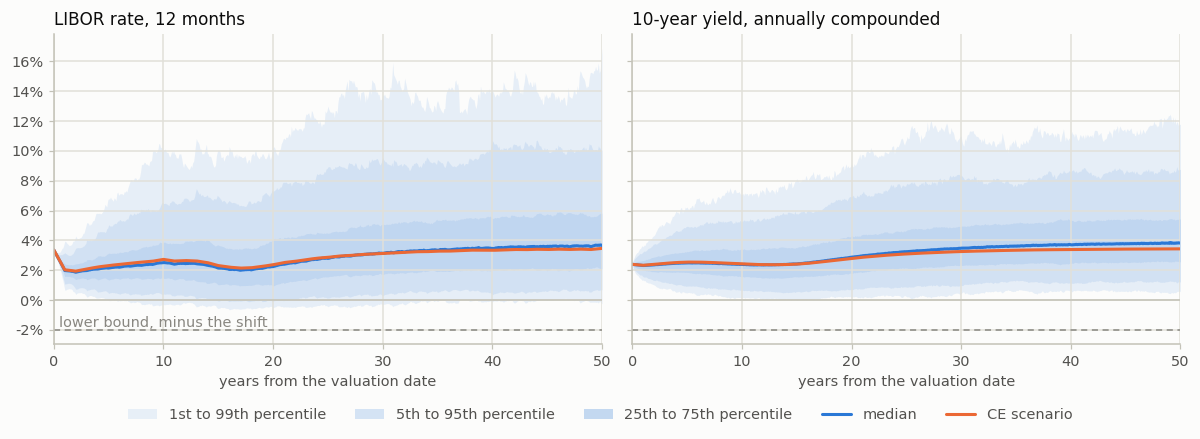

In [6]:
libor = lmm.libor_rate_paths()
yield10 = lmm.spot_rate_paths(120)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, paths, title in [(axes[0], libor, f"LIBOR rate, {p} months"),
                         (axes[1], yield10, "10-year yield, annually compounded")]:
    fan(ax, paths, years)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.axhline(-lmm.shift(), color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.set_title(title)
    ax.set_xlabel("years from the valuation date")
    ax.set_xlim(0, years[-1])
    percent_axis(ax.yaxis, 0.02)
axes[0].text(0.5, -lmm.shift(), "lower bound, minus the shift", color=MUTED, va="bottom")
fan_legend(fig, loc="lower center", ncols=5, bbox_to_anchor=(0.5, 0))
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

In [7]:
at = [y for y in (1, 5, 10, 20, 30, 50, 100, 150) if y * 12 <= n]
print(f"LIBOR rate (%): the CE value and percentiles of the stochastic scenarios")
display(percentile_table(libor, at))
print("10-year yield (%)")
display(percentile_table(yield10, at))

LIBOR rate (%): the CE value and percentiles of the stochastic scenarios


,CE,p1,p5,p25,p50,p75,p95,p99
year,,,,,,,,
1,2.03,0.66,1.06,1.58,1.98,2.43,3.17,3.94
5,2.31,-0.04,0.44,1.34,2.14,3.14,5.04,6.78
10,2.72,-0.31,0.40,1.45,2.50,3.88,6.47,10.06
20,2.36,-0.52,-0.06,0.95,2.24,4.09,7.26,10.21
30,3.12,-0.29,0.29,1.71,3.13,5.10,9.55,13.76
50,3.46,-0.25,0.68,2.10,3.65,5.83,10.07,16.88


10-year yield (%)


,CE,p1,p5,p25,p50,p75,p95,p99
year,,,,,,,,
1,2.33,1.34,1.56,2.00,2.31,2.65,3.23,3.57
5,2.54,0.48,0.94,1.85,2.49,3.26,4.94,6.24
10,2.42,0.18,0.66,1.55,2.39,3.42,5.27,7.07
20,2.79,0.17,0.71,1.77,2.87,4.31,6.93,9.14
30,3.25,0.44,0.98,2.34,3.48,4.96,8.38,10.99
50,3.43,0.56,1.20,2.58,3.82,5.40,8.77,11.75


## The deflators reproduce the initial curve

The mean deflator over the stochastic scenarios, divided by the initial discount factor,
should be 1 at every month: E[D(t)] = P^M(0, t). The band is the 95% Monte Carlo
interval, from the standard errors of antithetic pair means in
`Validation.martingale_test()`. In the first tenor period the deflators are known at
time 0, so the band starts at zero width. It widens with the horizon, as the deflators
spread out.

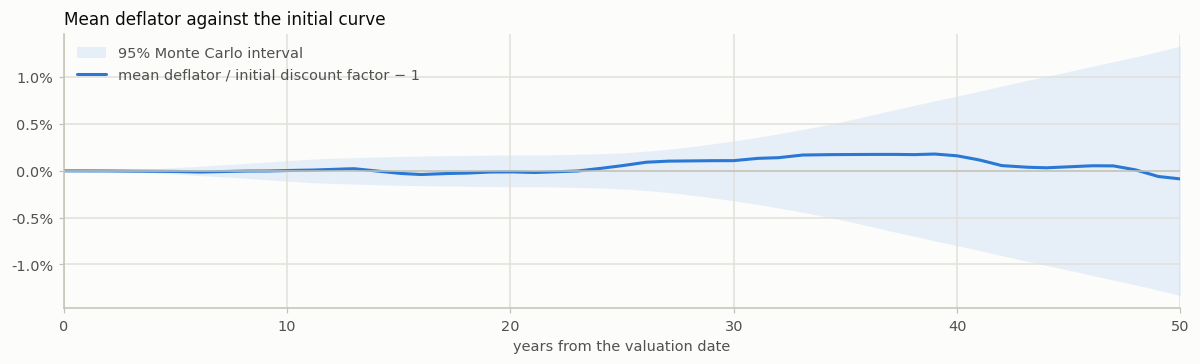

largest |z| over 600 months: 0.88


In [8]:
mart = validation.martingale_test()
ratio = mart["mc"] / mart["theory"] - 1
half_width = 1.96 * mart["se"] / mart["theory"]

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.fill_between(years, -half_width, half_width, color=BLUE, alpha=WASH, linewidth=0,
                label="95% Monte Carlo interval")
ax.plot(years, ratio, color=BLUE, label="mean deflator / initial discount factor − 1")
ax.axhline(0, color=AXIS, linewidth=1)
ax.set_title("Mean deflator against the initial curve")
ax.set_xlabel("years from the valuation date")
ax.set_xlim(0, years[-1])
percent_axis(ax.yaxis, 0.005, 1)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
print(f"largest |z| over {len(mart) - 1} months: {mart['z'].abs().max():.2f}")

## Caplets against Black's formula

The model moves the forward rates by a log-Euler step each month, which is not exact. The
caplets show how close it gets: for the rate set at every whole year, the Monte Carlo
price of an at-the-money caplet against Black's formula, from `Validation.caplet_test()`.
The band is the 95% Monte Carlo interval.

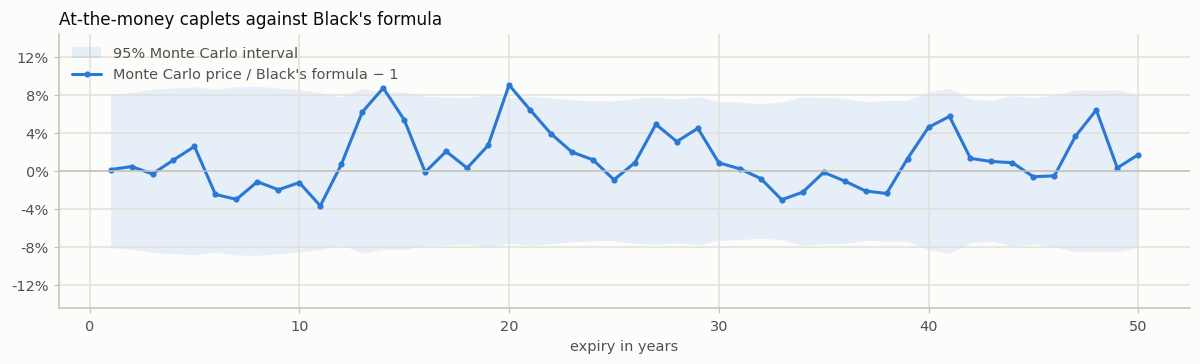

largest |z| over 50 caplets: 2.32


In [9]:
caplets = validation.caplet_test()
expiry = caplets.index.get_level_values("expiry")
ratio = caplets["mc"] / caplets["theory"] - 1
half_width = 1.96 * caplets["se"] / caplets["theory"]

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.fill_between(expiry, -half_width, half_width, color=BLUE, alpha=WASH, linewidth=0,
                label="95% Monte Carlo interval")
ax.plot(expiry, ratio, color=BLUE, marker="o", markersize=3,
        label="Monte Carlo price / Black's formula − 1")
ax.axhline(0, color=AXIS, linewidth=1)
limit = 1.6 * max(half_width.max(), ratio.abs().max())    # room for the legend
ax.set_ylim(-limit, limit)
ax.set_title("At-the-money caplets against Black's formula")
ax.set_xlabel("expiry in years")
percent_axis(ax.yaxis, 0.04)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
print(f"largest |z| over {len(caplets)} caplets: {caplets['z'].abs().max():.2f}")

## Distribution of the 10-year yield

Shifted-lognormal rates are skewed: the distribution has a long right tail and a short
left one, bounded by minus the shift. Each panel prints the share of scenarios with a
negative yield.

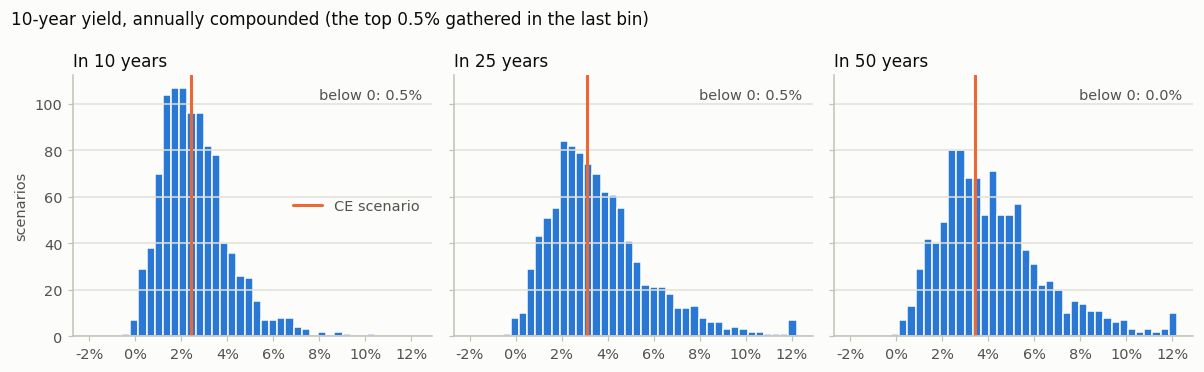

In [10]:
horizons = [y for y in (10, 25, 50) if y * 12 <= n]
values = yield10[1:, [12 * y for y in horizons]]
bins = np.linspace(min(-lmm.shift(), np.percentile(values, 0.1)), np.percentile(values, 99.5), 41)

fig, axes = plt.subplots(1, len(horizons), figsize=(11, 3.4), sharex=True, sharey=True)
for ax, horizon in zip(np.atleast_1d(axes), horizons):
    i = 12 * horizon
    ax.hist(np.clip(yield10[1:, i], bins[0], bins[-1]), bins=bins, color=BLUE,
            edgecolor=SURFACE, linewidth=1)
    ax.axvline(yield10[0, i], color=ORANGE, label="CE scenario")
    ax.text(0.97, 0.95, f"below 0: {(yield10[1:, i] < 0).mean():.1%}",
            transform=ax.transAxes, ha="right", va="top", color=INK_2)
    ax.set_title(f"In {horizon} years")
    ax.grid(axis="x", visible=False)
    percent_axis(ax.xaxis, 0.02)
first = np.atleast_1d(axes)[0]
first.set_ylabel("scenarios")
first.legend(loc="center right")
fig.suptitle("10-year yield, annually compounded (the top 0.5% gathered in the last bin)",
             x=0.01, ha="left", color=INK, fontsize=11)
fig.tight_layout()
plt.show()

## The tenor of the forward rates

The bank account rolls over at each tenor date at the rate just set, so with annual
forward rates its return is fixed for a year at a time, and bonds that mature within the
current year do not move. A shorter tenor makes the bank account follow a shorter rate.
The next cell overrides the tenor (`lmm.tenor_mth[()] = ...`) for a 10-year run, which
recalculates everything that depends on it, and restores the workbook's values at the
end with `clear_all()`. The same volatility table serves every tenor here, so the
deflators spread out more with a shorter tenor; a calibrated table belongs to one
tenor.

restored: tenor 12 months, 600 months


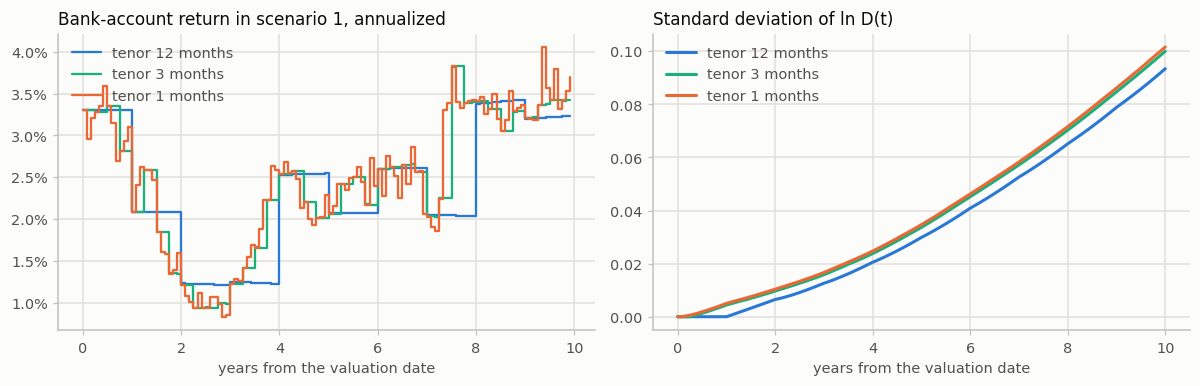

standard deviation of ln D(10): {12: 0.0934, 3: 0.1, 1: 0.1016}


In [11]:
tenors, bank, spread = (12, 3, 1), {}, {}
lmm.step_size[()] = 120
for tenor in tenors:
    lmm.tenor_mth[()] = tenor
    bank[tenor] = lmm.bank_return_paths()[1] * 12            # scenario 1, annualized
    spread[tenor] = np.log(lmm.disc_factor_paths()[1:]).std(axis=0)
lmm.tenor_mth.clear_all()
lmm.step_size.clear_all()
print(f"restored: tenor {lmm.tenor_mth()} months, {lmm.step_size()} months")

ten = np.arange(121) / 12
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
for tenor, color in zip(tenors, [BLUE, GREEN, ORANGE]):
    left.step(ten[:-1], bank[tenor], where="post", color=color, linewidth=1.5,
              label=f"tenor {tenor} months")
    right.plot(ten, spread[tenor], color=color, label=f"tenor {tenor} months")
left.set_title("Bank-account return in scenario 1, annualized")
left.set_xlabel("years from the valuation date")
percent_axis(left.yaxis, 0.005, 1)
left.legend(loc="upper left")
right.set_title("Standard deviation of ln D(t)")
right.set_xlabel("years from the valuation date")
right.legend(loc="upper left")
fig.tight_layout()
plt.show()
print("standard deviation of ln D(10):", {t: round(float(s[-1]), 4) for t, s in spread.items()})

## The bond fund

The liability model's fund holds the shares of the `Fund` sheet: zero-coupon bonds by
years to maturity, rebalanced monthly, plus cash. The left panel shows the growth of 1
invested at time 0. Because the fund holds only bonds and the bank account, its deflated
value is a martingale; the right panel checks that its mean stays at 1.

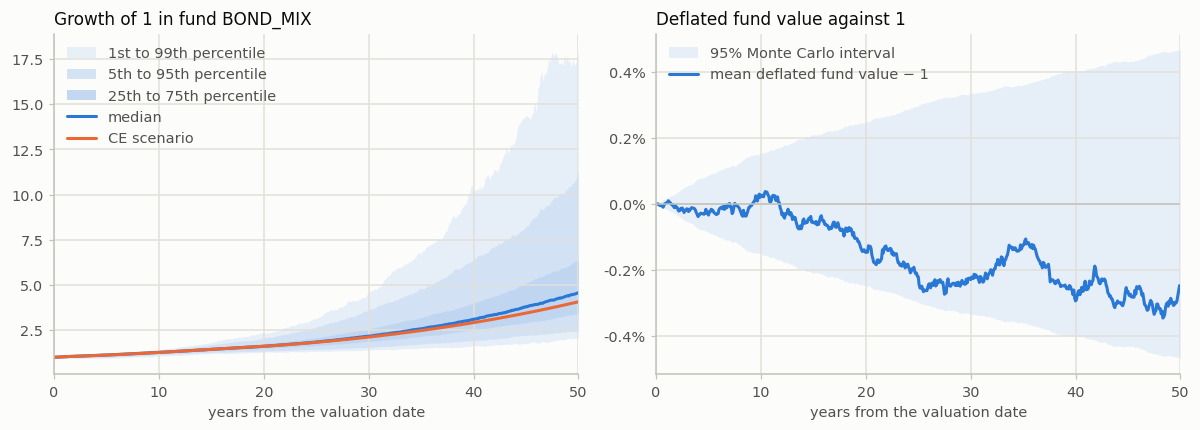

Growth of 1 in fund BOND_MIX: the CE value and percentiles


,CE,p1,p5,p25,p50,p75,p95,p99
year,,,,,,,,
1,1.034,0.960,0.980,1.014,1.035,1.055,1.082,1.097
5,1.122,0.942,1.011,1.087,1.127,1.162,1.208,1.228
10,1.267,1.078,1.148,1.222,1.272,1.314,1.381,1.422
20,1.609,1.281,1.348,1.491,1.611,1.758,2.061,2.342
30,2.119,1.410,1.538,1.876,2.168,2.580,3.594,4.564
50,4.070,2.016,2.473,3.461,4.578,6.389,11.118,18.051


In [12]:
returns = lmm.fund_return_paths()
growth = np.cumprod(np.hstack([np.ones((N + 1, 1)), 1 + returns]), axis=1)
fund_mart = validation.fund_martingale_test()

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
fan(left, growth, years)
left.set_title(f"Growth of 1 in fund {lmm.fund_id()}")
left.set_xlabel("years from the valuation date")
left.set_xlim(0, years[-1])
fan_legend(left, loc="upper left")

half_width = 1.96 * fund_mart["se"]
right.fill_between(years, -half_width, half_width, color=BLUE, alpha=WASH, linewidth=0,
                   label="95% Monte Carlo interval")
right.plot(years, fund_mart["mc"] - 1, color=BLUE, label="mean deflated fund value − 1")
right.axhline(0, color=AXIS, linewidth=1)
right.set_title("Deflated fund value against 1")
right.set_xlabel("years from the valuation date")
right.set_xlim(0, years[-1])
percent_axis(right.yaxis, 0.002, 1)
right.legend(loc="upper left")
fig.tight_layout()
plt.show()

print(f"Growth of 1 in fund {lmm.fund_id()}: the CE value and percentiles")
display(percentile_table(growth, at, scale=1, decimals=3))

## Validation summary

Each test compares Monte Carlo estimates with the values they should converge to, as
z-scores. A test with m z-scores passes if its largest |z| is below the limit
Φ⁻¹(1 − 0.00135/m): the same 0.27% chance of a false alarm as a single 3-sigma check,
so the limit is 3 for one check and about 4.6 for 600 months. A test whose estimate is
exact by construction scores 0. For a new calibration, run this with `scen_size` set to
10,000.

In [13]:
validation.summary()

,checks,max_abs_z,limit,ok,at
martingale_test(),601,0.883662,4.587190,True,324
fund_martingale_test(),601,1.717591,4.587190,True,4
curve_fit_test(),50,0.884137,4.037604,True,27.0
caplet_test(),50,2.316520,4.037604,True,"(21, 20.0)"
"zcb_martingale_test(300, 420)",1,1.550688,2.999977,True,"(300, 420)"


`swaption_test` is a diagnostic rather than a test: it compares the Monte Carlo price
of an at-the-money payer swaption with Rebonato's approximation of its volatility, which
freezes the weights of the forward rates at time 0. The approximation is usually within a
few percent at the money.

In [14]:
pd.concat([validation.swaption_test(a, b).assign(
    approx_vol=validation.swaption_vol(a, b)) for a, b in ((5, 5), (10, 10), (20, 10))])

,,mc,theory,se,z,approx_vol
a,b,,,,,
5,5,0.020912,0.020703,0.000877,0.238836,0.125745
10,10,0.037119,0.037762,0.001306,-0.492191,0.098275
20,10,0.035775,0.034352,0.001059,1.343203,0.075147
